In [39]:
import sounddevice as sd
import scipy.signal
import soundfile as sf
import matplotlib.pyplot as plt
import numpy as np


In [2]:
sd.get_portaudio_version()
devices = sd.query_devices()
print(len(devices))

0


In [3]:
freq = 44100
duration = 5
recording = sd.rec(int(duration * freq), samplerate=freq, channels=1)
sd.wait()

PortAudioError: Error querying device -1

In [21]:
wf, sampling_freq = sf.read("potters.wav")

# get only one channel
if len(wf.shape) > 1:
    wf = wf[:, 0]

In [36]:
# do a low-pass filter
# N is the order
# Wn is the critical frequency in Hz (ie cutoff)
b, a = scipy.signal.butter(N=5, Wn=120.0, fs=sampling_freq, btype="low", analog=False)
filtered_wf = scipy.signal.lfilter(b, a, wf)

/tmp/ipykernel_10741/1051688986.py:3: RuntimeWarning: divide by zero encountered in log
  plt.pcolormesh(t, f, np.log(Sxx), shading='gouraud')


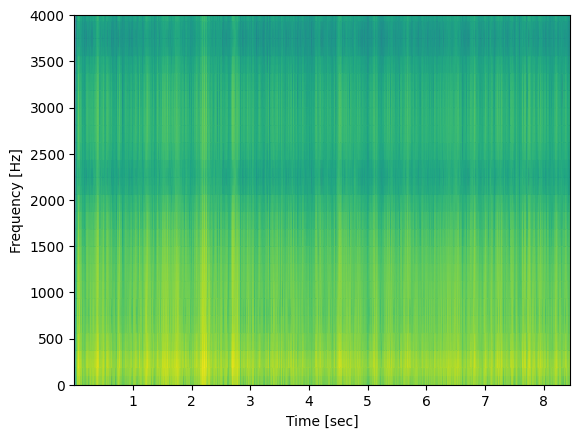

In [ ]:
# need to grab only one channel
f, t, Sxx = scipy.signal.spectrogram(wf, fs=sampling_freq)
plt.pcolormesh(t, f, np.log(Sxx), shading="gouraud")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [sec]")
plt.ylim(0, 4000)
plt.show()

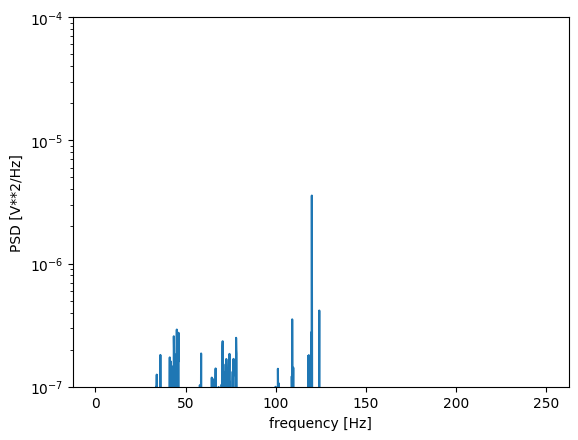

In [38]:
f, Pxx_den = scipy.signal.periodogram(filtered_wf, fs=sampling_freq)
i = f < 250
plt.semilogy(f[i], Pxx_den[i])
plt.ylim([1e-7, 1e-4])
plt.xlabel("frequency [Hz]")
plt.ylabel("PSD [V**2/Hz]")
plt.show()